In [1]:
import os
import pandas as pd
import soundfile as sf
import librosa
from IPython.display import Audio
from tqdm import tqdm
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import os
import random
from IPython.display import Audio, display
import os
from multiprocessing import Pool
from tqdm import tqdm
from pathlib import Path
import random
tqdm.pandas()

# CODA

In [11]:
tb_condition_map = {
    "tb_prior": 1,             # 2^0
    "tb_prior_Pul": 2,         # 2^1
    "tb_prior_Extrapul": 4,    # 2^2
    "tb_prior_Unknown": 8      # 2^3
}

def process_resp_ill_numeric(row):
    code = 0
    for cond, weight in tb_condition_map.items():
        if row[cond] == "Yes":
            code += weight
    return code

In [14]:
coda_root = "/run/media/fourier/Data1/Pras/Database_ThesisNew/TB/Data/Train/"
df_coda_extra = pd.read_csv(f'{coda_root}/meta_data/Clinical/CODA_TB_additional_variables_train.csv')
clinical_df = pd.read_csv(f"{coda_root}/meta_data/Clinical/CODA_TB_Clinical_Meta_Info.csv")
clinical_df["prior_type"] = clinical_df.apply(process_resp_ill_numeric, axis=1)
clinical_df = df_coda_extra.merge( clinical_df, on="participant", how="left" )
clinical_df = clinical_df[['participant', 'sex', 'age', 'Country',
          'weight_loss', 'hemoptysis', 'night_sweats', 'smoke_lweek', 'fever', 'reported_cough_dur', 'tb_prior', 'prior_type', 'HIVstatus',
            'Microbiologicreferencestandard', 'Sputumxpertreferencestandard', 'Xpertcombinedsemiquant', 'tb_status']]

cols = ['weight_loss', 'hemoptysis', 'night_sweats', 'smoke_lweek', 'fever', 'tb_prior']
clinical_df[cols] = (
    clinical_df[cols]
    .replace({"Not sure": np.nan, "Yes": 1, "No": 0})
    .fillna(-1)
    .astype(int)
)

cols = ['Microbiologicreferencestandard', 'Sputumxpertreferencestandard', "HIVstatus"]
clinical_df[cols] = (
    clinical_df[cols]
    .replace({"Indeterminate": np.nan, "Unknown": -1, "Positive": 1, "Negative": 0})
    .fillna(-1)
    .astype(int)
)
clinical_df["Xpertcombinedsemiquant"] = clinical_df["Xpertcombinedsemiquant"].fillna(0).map({0: 0, "Trace": 1, "Very low": 2, "Low": 3, "Medium": 4, "High": 5})

df_coda = pd.read_csv(f"{coda_root}/meta_data/Cough Metadata/CODA_TB_Solicited_Meta_Info.csv")
df_coda["path_file"] = coda_root + "/raw_data/solicited_data/" + df_coda["filename"]
df_coda = df_coda[df_coda["path_file"].progress_apply(os.path.isfile)].reset_index(drop=True)
df_coda = df_coda.merge(
    clinical_df,
    on="participant",
    how="left"
)

/tmp/ipykernel_173861/1608360716.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({"Not sure": np.nan, "Yes": 1, "No": 0})
/tmp/ipykernel_173861/1608360716.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({"Indeterminate": np.nan, "Unknown": -1, "Positive": 1, "Negative": 0})
100%|██████████| 9772/9772 [00:00<00:00, 357569.30it/s]


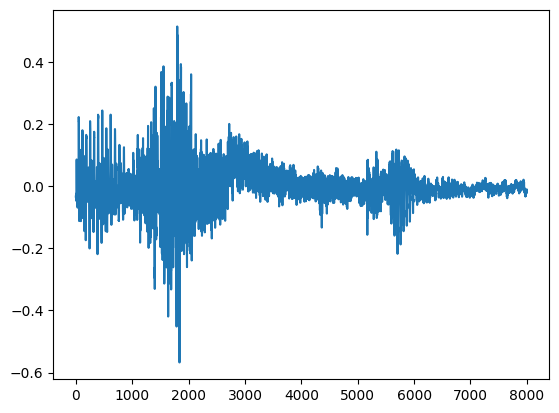

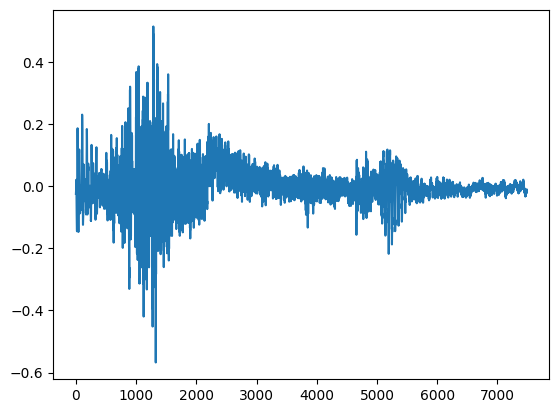

In [16]:
wav_list = df_coda['path_file'].values
wavfilename = random.choice(wav_list)
wav_path = os.path.join(wavfilename)

audio, fs = librosa.load(wav_path, sr=16000)
audio = audio - np.mean(audio)
now_segment = audio

_, idx = librosa.effects.trim(now_segment, top_db=5)
x_trimmed = now_segment[idx[0]:]

display(Audio(x_trimmed, rate=fs))

plt.plot(now_segment)
plt.show()

plt.plot(x_trimmed)
#plt.plot(x_trimmed)

In [17]:
def process_row(row):
    wav_path = row["path_file"]
    filename = wav_path.split("/")[-1].split(".")[0]

    audio, fs = librosa.load(wav_path, sr=16000)
    audio = audio - np.mean(audio)

    _, idx = librosa.effects.trim(audio, top_db=15)
    now_segment = audio
    if (len(now_segment[idx[0]:]) / fs) >= 0.3:
        now_segment = now_segment[idx[0]:]

    out_path = f"data/wavs/coda/{filename}.wav"
    sf.write(out_path, now_segment, fs)

    row["path_file"] = out_path
    row["duration"] = len(now_segment) / fs
    return row

os.makedirs("data/wavs/coda", exist_ok=True)
rows = df_coda.to_dict("records")
with Pool(processes=16) as pool:
    out_rows = list(
        tqdm(
            pool.imap(process_row, rows),
            total=len(rows)
        )
    )

df_collate = pd.DataFrame(out_rows)
df_collate = df_collate[
    df_collate["duration"].between(0.35, 0.5)
].reset_index(drop=True)
df_collate.to_csv(f"data/coda.csv", index=False)
len(df_collate)

100%|██████████| 9772/9772 [00:07<00:00, 1235.63it/s]


9580

# TBScreen

In [5]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import hilbert
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

TBScreen = "/run/media/fourier/Data1/Pras/DatabaseLLM/TBscreen_Dataset"
wav_list = (
    [os.path.join(f"{TBScreen}/Forced_coughs/Audio_files", f) for f in os.listdir(f"{TBScreen}/Forced_coughs/Audio_files")]
    + [os.path.join(f"{TBScreen}/Passive_coughs/Audio_files", f) for f in os.listdir(f"{TBScreen}/Passive_coughs/Audio_files")]
)

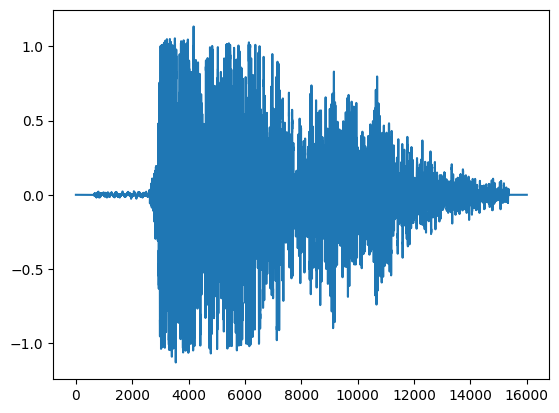

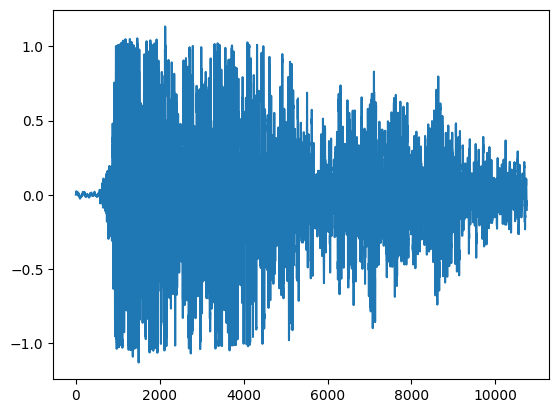

In [6]:
wavfilename = random.choice(wav_list)
wav_path = os.path.join(wavfilename)

audio, fs = librosa.load(wav_path, sr=16000)
audio = audio - np.mean(audio)
now_segment = audio

x_trimmed, idx = librosa.effects.trim(now_segment, top_db=15)
#x_trimmed = now_segment[idx[0]:]

plt.plot(now_segment)
plt.show()

plt.plot(x_trimmed)
plt.show()

In [7]:
df_longi = pd.read_csv("/run/media/fourier/Data1/Pras/DatabaseLLM/TBscreen_Dataset/Passive_coughs/Passive_coughs.csv")
df_solic = pd.read_csv("/run/media/fourier/Data1/Pras/DatabaseLLM/TBscreen_Dataset/Forced_coughs/Forced_coughs.csv")

df_longi['path'] = "/run/media/fourier/Data1/Pras/DatabaseLLM/TBscreen_Dataset/Passive_coughs/Audio_files/" + df_longi['path'] +  ".wav"
df_longi['subject_device'] = df_longi['subject'] + "_" + df_longi['device']
df_longi['type'] = 'longi'

df_solic['path'] = "/run/media/fourier/Data1/Pras/DatabaseLLM/TBscreen_Dataset/Forced_coughs/Audio_files/" + df_solic['path'] +  ".wav"
df_solic['subject_device'] = df_solic['subject'] + "_" + df_solic['device']
df_solic['type'] = 'solic'

df_solic['file_exists'] = df_solic['path'].progress_apply(lambda x: os.path.exists(str(x)))
df_solic = df_solic[df_solic['file_exists']].drop(columns=['file_exists']).reset_index(drop=True)

df_longi['file_exists'] = df_longi['path'].progress_apply(lambda x: os.path.exists(str(x)))
df_longi = df_longi[df_longi['file_exists']].drop(columns=['file_exists']).reset_index(drop=True)

df_solic.reset_index(drop=True, inplace=True)
df_longi.reset_index(drop=True, inplace=True)

cols_longi = set(df_longi.columns)
cols_solic = set(df_solic.columns)

# Columns only in df_longi
print("Only in df_longi:")
print(sorted(cols_longi - cols_solic))

# Columns only in df_solic
print("\nOnly in df_solic:")
print(sorted(cols_solic - cols_longi))

df_longi = df_longi.drop(
    columns=["S.NO", "all_device_cough_count", "single_device_cough_count"],
    errors="ignore"
)

df_solic = df_solic.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

assert set(df_longi.columns) == set(df_solic.columns)
df_tbscreen = pd.concat([df_longi, df_solic], ignore_index=True)
df_tbscreen = df_tbscreen.fillna("unknown")
df_tbscreen['type'].value_counts()

/tmp/ipykernel_127293/3957483486.py:1: DtypeWarning: Columns (28,29,32,38) have mixed types. Specify dtype option on import or set low_memory=False.
  df_longi = pd.read_csv("/run/media/fourier/Data1/Pras/DatabaseLLM/TBscreen_Dataset/Passive_coughs/Passive_coughs.csv")
  0%|          | 0/33641 [00:00<?, ?it/s]

100%|██████████| 33641/33641 [00:00<00:00, 362819.70it/s]

Only in df_longi:
['S.NO', 'all_device_cough_count', 'single_device_cough_count']

Only in df_solic:
['Unnamed: 0']


type
longi    27343
solic     1018
Name: count, dtype: int64

In [10]:
def process_row(row):
    wav_path = row["path"]
    filename = wav_path.split("/")[-1].split(".")[0]

    audio, fs = librosa.load(wav_path, sr=16000)
    audio = audio - np.mean(audio)

    _, idx = librosa.effects.trim(audio, top_db=5)
    now_segment = audio[idx[0]:]
        
    out_path = (
        f"data/wavs/tbscreen/"
        f"{row['type']}_{filename}.wav"
    )
    sf.write(out_path, now_segment, fs)

    row["path_file"] = out_path
    row["duration"] = len(now_segment) / fs
    return row

os.makedirs("data/wavs/tbscreen", exist_ok=True)
rows = df_tbscreen.to_dict("records")
with Pool(processes=8) as pool:
    out_rows = list(
        tqdm(
            pool.imap(process_row, rows),
            total=len(rows)
        )
    )
df_collate = pd.DataFrame(out_rows)
df_collate = df_collate[
    df_collate["duration"].between(0.35, 1.0)
].reset_index(drop=True)
df_collate.to_csv(f"data/tbscreen.csv", index=False)

100%|██████████| 28361/28361 [00:12<00:00, 2305.17it/s]


# CIDRZ

In [ ]:
import sys
CAD_DIR = "/run/media/fourier/Data1/Pras/Thesis_Nexus/NXSCough/deploy/cad"
if CAD_DIR not in sys.path:
    sys.path.insert(0, CAD_DIR)

os.environ.setdefault("OMP_NUM_THREADS", "1")
_CAD_DET = None
from infer import CADDetector
_CAD_DET = CADDetector(CAD_DIR)

def cad_segment_coughs(audio, sr, min_len_samples=int(0.35 * 16000), energy_gate=True, energy_gate_db=30):
    """Frame-level CAD replacement for phase1_segment_coughs.

    Returns {"segments": [np.ndarray], "events": [{start,end,score}], "mask": np.ndarray}:
      segments - the slice of `audio` for each detected cough (bout-splitting on)
      mask     - int8 array, len == len(audio), 1 inside a cough event else 0."""
    
    events = _CAD_DET.events_from_wav(np.asarray(audio, dtype=np.float32), energy_gate=energy_gate, energy_gate_db=energy_gate_db)
    n = len(audio)
    mask = np.zeros(n, dtype=np.int8)
    segments, kept = [], []
    for ev in events:
        a, b = int(ev["start"] * sr), int(ev["end"] * sr)
        seg = audio[a:b]
        if len(seg) >= min_len_samples:
            probs = _CAD_DET.posterior_from_wav(seg, chunk_sec=0.0)
            if float(probs.mean()) >= 0.5:
                segments.append(seg)
                kept.append(ev)
                mask[a:b] = 1
    
    new_segment = []
    for i, segment in enumerate(segments):
        try:
            temp_segment = segment
            new_segment.append(temp_segment)
        except:
            pass

    return {"segments": new_segment, "events": kept, "mask": mask}

import warnings
warnings.filterwarnings("ignore", message="n_fft=.*too large")

LABEL_FOLDER_MAP = {"Audio-Recorder": 0, "Phone A": 1, "Phone B": 2, "Phone C": 3}
FACILITIES_MAP   = {"Chainda": 0, "Chawama": 1, "Kanyama": 2}

In [39]:
cidrz_root = "/run/media/fourier/Data1/Pras/DatabaseLLM/cirdz/raw"
df = pd.read_csv(f"{cidrz_root}/Metadata and Codebook/GHAI_Final_Data_2023.csv")
df['ground_truth_tb'].value_counts()

root_dir = Path(cidrz_root)
wav_files = list(root_dir.rglob("*.wav"))

df_cidrz = pd.DataFrame(columns=list(df.columns) + ["phone_code", "path_file"])
for wav_path in tqdm(wav_files, total=len(wav_files)):
    wav_path = str(wav_path)
    metadata = wav_path.split("/")

    phone_now_code = 9
    for phone_type in LABEL_FOLDER_MAP.keys():
        if phone_type in metadata[-2]:
            phone_now_code = LABEL_FOLDER_MAP[phone_type]

    selected_row = df[df["barcode"] == metadata[-1].split(".")[0]]
    if selected_row.empty:
        continue

    selected_row = selected_row.copy()
    selected_row["phone_code"] = phone_now_code
    selected_row["path_file"] = wav_path
    df_cidrz = pd.concat([df_cidrz, selected_row], ignore_index=True)


  0%|          | 0/1449 [00:00<?, ?it/s]

/tmp/ipykernel_127293/83487880.py:25: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_cidrz = pd.concat([df_cidrz, selected_row], ignore_index=True)
100%|██████████| 1449/1449 [00:00<00:00, 1838.37it/s]


In [43]:
SR = 16000
SAVE_DIR = Path("data/wavs/cidrz")
SAVE_DIR.mkdir(exist_ok=True)

MIN_LEN_SAMPLES = int(0.25 * SR)
n_workers = os.cpu_count() or 4
rows = df_cidrz.to_dict("records")

print(df_cidrz['ground_truth_tb'].value_counts())

ground_truth_tb
neg    1102
pos     209
Name: count, dtype: int64


In [44]:
def process_row(args):
    """
    Process one metadata row.

    Returns (out_rows, fail_path):
      out_rows  : list of new row dicts (one per written segment)
      fail_path : the source path if phase1 produced zero segments, else None
    """
    idx, row_dict = args
    path_file = row_dict["path_file"]
    try:
        audio, sr = librosa.load(path_file, sr=SR, mono=True)
    except Exception:
        return [], None
    
    try:
        result_segment = cad_segment_coughs(audio, sr, min_len_samples=MIN_LEN_SAMPLES, energy_gate=False, energy_gate_db=10)
    except Exception:
        return [], None

    if len(result_segment["segments"]) == 0:
        return [], path_file

    stem = Path(path_file).stem
    out_rows = []
    for i, segment in enumerate(result_segment["segments"]):
        probs = _CAD_DET.posterior_from_wav(segment, chunk_sec=0.0)
        out_path = SAVE_DIR / f"{stem}_{row_dict['facility_code']}_{row_dict['phone_code']}_{idx}_{i}.wav"
        sf.write(out_path, segment, sr)

        new_dict = dict(row_dict)
        new_dict["path_file"] = str(out_path)
        new_dict["cad_probs"] = float(probs.mean())
        out_rows.append(new_dict)

    return out_rows, None

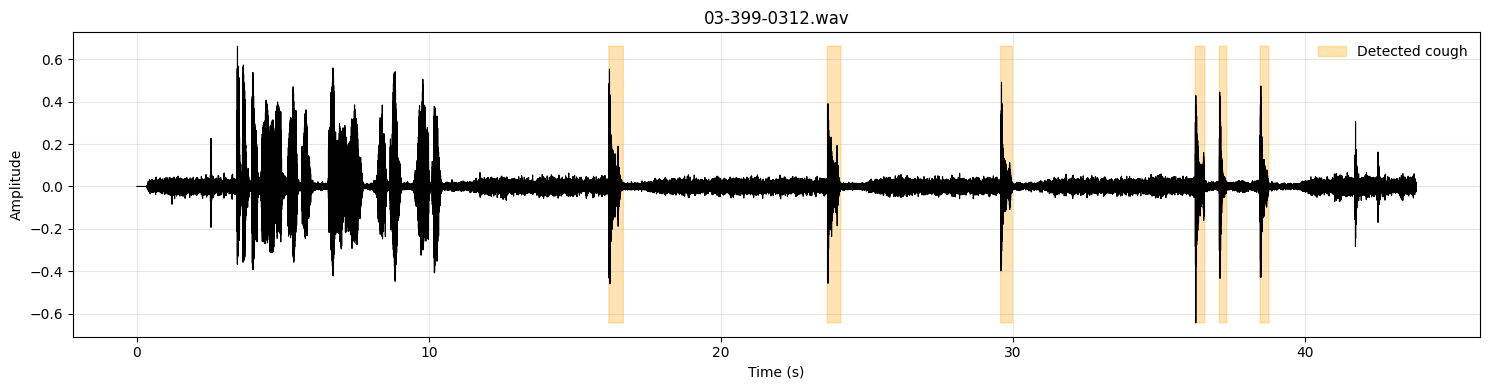

In [42]:
path = df_cidrz[(df_cidrz['facility_code'] == "Chai") & (df_cidrz['phone_code'] == 2) & (df_cidrz['ground_truth_tb'] == 'pos')]["path_file"].sample().iloc[0]
audio, sr = librosa.load(path, sr=16000, mono=True)

# Detect coughs
result_segment = cad_segment_coughs(audio, sr, min_len_samples=MIN_LEN_SAMPLES, energy_gate=False, energy_gate_db=10)
mask = result_segment["mask"].astype(bool)

# Plot
fig, ax = plt.subplots(figsize=(15, 4))
t = np.arange(len(audio)) / sr
ax.plot(t, audio, color="black", linewidth=0.8)

# Highlight cough regions
ax.fill_between(
    t,
    audio.min(),
    audio.max(),
    where=mask,
    color="orange",
    alpha=0.3,
    interpolate=True,
    label="Detected cough"
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title(path.split("/")[-1])
ax.legend(frameon=False)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
new_rows = []
fail_rows = []
with Pool(processes=n_workers, maxtasksperchild=50) as pool:
    for out_rows, fail_path in tqdm(pool.imap_unordered(process_row, enumerate(rows)), total=len(rows)):
        new_rows.extend(out_rows)
        if fail_path is not None:
            fail_rows.append(fail_path)

df_new = pd.DataFrame(new_rows)

100%|██████████| 1311/1311 [03:48<00:00,  5.74it/s]


In [48]:
df_cough = df_new[df_new['cad_probs'] >= 0.75].reset_index(drop=True)
df_cough = df_cough[['path_file', 'sex', 'barcode', 'facility_code', 'phone_code', 'anon_id',
                     'coughdur', 'cough_productive', 'haemoptysis', 'chestpain', 'shortbreath', 'fever', 'ngtsweats', 
                     'weightloss', 'hiv_status', 'prev_tb', 'prevtb_episodes', 'tobacco_use',
                      'lam_results', 'sm_results', 'smear_all', 'xpert_results', 'culture_results', 'type_tb', 'ground_truth_tb',
                     'cad_probs']]

# df_cough.groupby( ['phone_code', 'ground_truth_tb', 'facility_code'] ).size().reset_index(name='count')
df_cough["xpert_results"] = df_cough["xpert_results"].map({"neg": 0, "trace_call": 2, "pos": 1}).fillna(-1).astype(int)
df_cough["culture_results"] = df_cough["culture_results"].map({"no tb": 0, "tb": 1, "ntm": 2}).fillna(-1).astype(int)
df_cough["tobacco_use"] = df_cough["tobacco_use"].map({"never": 0, "current": 1, "stopped": 1}).fillna(-1).astype(int)

cols = ["hiv_status", "ground_truth_tb", "lam_results", "smear_all"]
df_cough[cols] = (
    df_cough[cols]
    .replace({"": np.nan, "pos": 1, "neg": 0})
    .fillna(-1)
    .astype(int)
)

cols = ["haemoptysis", "chestpain", "shortbreath", "fever", "ngtsweats", "weightloss", "prev_tb", "cough_productive"]
df_cough[cols] = (
    df_cough[cols]
    .replace({"": np.nan, "yes": 1, "no": 0})
    .fillna(-1)
    .astype(int)
)
df_cough.to_csv("data/cidrz.csv", index=False)

/tmp/ipykernel_127293/469432797.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({"": np.nan, "pos": 1, "neg": 0})
/tmp/ipykernel_127293/469432797.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({"": np.nan, "yes": 1, "no": 0})


# Combine

In [15]:
import numpy as np
import pandas as pd
import soundfile as sf

def get_duration(path):
    try:
        with sf.SoundFile(path) as f:
            return len(f) / f.samplerate
    except Exception:
        return None

In [16]:
df_solic = pd.read_csv('data/coda.csv')
df_solic['sex'] = df_solic['sex'].replace({'Male': 0, 'Female': 1})
df_solic = df_solic.rename(columns={"tb_status": "disease_status",
                                    "sex": "gender", "smoke_lweek": "smoker", "hemoptysis": "hemoptysis", 
                                    "night_sweats": "night_sweats", "weight_loss": "weight_loss", 
                                    "HIVstatus": 'hiv', 'Country': 'db_additional'})
df_solic["db"] = 0
df_solic["split"] = 'train'
df_solic = df_solic[['path_file', 'participant', 'gender', 'disease_status', 'weight_loss', 'hemoptysis', 'smoker', 'night_sweats', 'hiv', 'db', 'db_additional']]
df_solic["participant_original"] = "CODA_" + df_solic["participant"]
df_solic["participant"] = df_solic["participant"].astype("category").cat.codes
df_solic["participant"] = 0 + df_solic["participant"]

/tmp/ipykernel_187363/1179025326.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_solic['sex'] = df_solic['sex'].replace({'Male': 0, 'Female': 1})


In [17]:
df_cirdz = pd.read_csv('data/cidrz.csv')
df_cirdz['sub_code'] = df_cirdz['barcode'].astype(str) + "_" + df_cirdz['facility_code'].astype(str) + "_" + df_cirdz['phone_code'].astype(str)
df_cirdz['db_additional'] = df_cirdz['facility_code'].astype(str) + "_" + df_cirdz['phone_code'].astype(str)
df_cirdz = (
    df_cirdz
    .groupby("sub_code", group_keys=False)
    .apply(lambda x: x.sample(n=min(15, len(x)), random_state=42))
    .reset_index(drop=True)
)
counts = df_cirdz.groupby("sub_code").size()
print(counts.describe())

df_cirdz['sex'] = df_cirdz['sex'].replace({'m': 0, 'f': 1})
df_cirdz = df_cirdz.rename(columns={"ground_truth_tb": "disease_status", "anon_id": "participant",
                                    "sex": "gender", "tobacco_use": "smoker", "haemoptysis": "hemoptysis", 
                                    "ngtsweats": "night_sweats", "weightloss": "weight_loss", "body_wt": "weight", 
                                    "height": "height", "hiv_status": 'hiv'})
df_cirdz["db"] = 1
df_cirdz["split"] = 'train'
df_cirdz = df_cirdz[['path_file', 'participant', 'gender', 'disease_status', 'weight_loss', 'hemoptysis', 'smoker', 'night_sweats', "hiv", "db", "db_additional"]]
df_cirdz["participant_original"] = "CIDRZ_" + df_cirdz["participant"].astype(str)
df_cirdz["participant"] = df_cirdz["participant"].astype("category").cat.codes
df_cirdz["participant"] = 1000 + df_cirdz["participant"]

count    1284.000000
mean        6.619938
std         1.750744
min         1.000000
25%         6.000000
50%         6.000000
75%         7.000000
max        15.000000
dtype: float64


/tmp/ipykernel_187363/2056546540.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(15, len(x)), random_state=42))
/tmp/ipykernel_187363/2056546540.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cirdz['sex'] = df_cirdz['sex'].replace({'m': 0, 'f': 1})


In [18]:
df_tbscreen  = pd.read_csv("data/tbscreen.csv")
df_tbscreen['subject'] = df_tbscreen['sub'].astype(str) + df_tbscreen['cohort']
df_tbscreen['sub_code'] = df_tbscreen['device'].astype(str) + "_" + df_tbscreen['sub'].astype(str) + df_tbscreen['cohort'] + "_" + df_tbscreen['type'].astype(str)
df_tbscreen = (
    df_tbscreen
    .groupby("sub_code", group_keys=False)
    .apply(lambda x: x.sample(n=min(35, len(x)), random_state=42))
    .reset_index(drop=True)
)
df_tbscreen['Label'] = df_tbscreen['Label'].replace({'NTB': 0, 'TB': 1})
df_tbscreen = df_tbscreen.rename(columns={"subject": "participant", "gndr_a": "gender", "smkr_a": "smoker", "un_wght_loss": "weight_loss", 
                                    "nght_swts": "night_sweats", "cough_bld": "hemoptysis", "hiv_infected_a" : 'hiv', "Label": "disease_status", "device" : "db_additional"})
df_tbscreen["db"] = 2
df_tbscreen["split"] = 'train'
df_tbscreen = df_tbscreen[['path_file', 'participant', 'gender', 'disease_status', 'weight_loss', 'hemoptysis', 'smoker', 'night_sweats', 'hiv', 'split', 'db', "db_additional", 'type']]

cols = [ "gender", "disease_status", "weight_loss", "hemoptysis", "smoker", "night_sweats", "hiv"]
df_tbscreen[cols] = df_tbscreen[cols].replace("unknown", 0)
df_tbscreen[cols] = df_tbscreen[cols].astype(float)
df_tbscreen = df_tbscreen[['path_file', 'participant', 'gender', 'disease_status', 'weight_loss', 'hemoptysis', 'smoker', 'night_sweats', 'hiv', 'db', "db_additional"]]
df_tbscreen["participant_original"] = "TBScreen_" + df_tbscreen["participant"]
df_tbscreen["participant"] = df_tbscreen["participant"].astype("category").cat.codes
df_tbscreen["participant"] = 2000 + df_tbscreen["participant"]

/tmp/ipykernel_187363/385938876.py:1: DtypeWarning: Columns (4,6,7,13,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_tbscreen  = pd.read_csv("data/tbscreen.csv")
/tmp/ipykernel_187363/385938876.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(35, len(x)), random_state=42))
/tmp/ipykernel_187363/385938876.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_tbscreen[cols] = df_tbscreen[cols].replace("u

In [19]:
df_concat = pd.concat([df_solic, df_cirdz, df_tbscreen], axis=0, ignore_index=True)
df_concat["duration_sec"] = df_concat["path_file"].apply(get_duration)
df_concat = df_concat[
    (df_concat["duration_sec"] >= 0.3) &
    (df_concat["duration_sec"] <= 1.2)
].reset_index(drop=True)

In [20]:
# Mean duration for each database
mean_duration = (
    df_concat
    .groupby("db")["duration_sec"]
    .mean()
    .sort_values()
)

print(mean_duration)

db
1    0.413022
0    0.416982
2    0.738849
Name: duration_sec, dtype: float64


In [21]:
df_concat.to_csv("data/combine.csv", index=False)